In [1]:
# Imports
import copy
import os
import random
import shutil
import zipfile
from math import atan2, cos, sin, sqrt, pi, log

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from numpy import linalg as LA
from torch import optim, nn
from torch.utils.data import DataLoader, random_split
from torchvision import transforms
from tqdm import tqdm

In [ ]:
from carvana_dataset import CarvanaDataset

dataset = CarvanaDataset(root_path="/home/savio/Documents/modeling_generation/data/carvana-image-masking-challenge")

In [3]:
# Split the dataset into training and validation sets
generator = torch.Generator().manual_seed(25)

train_dataset, val_dataset = random_split(dataset, [0.8, 0.2], generator=generator)


In [4]:
# Set the device and number of workers for data loading
device = "cuda" if torch.cuda.is_available() else "cpu"

if device == "cuda":
    num_workers = torch.cuda.device_count() * 4

In [5]:
# Create the data loaders for training and validation

BATCH_SIZE = 8

train_dataloader = DataLoader(dataset=train_dataset,
                              batch_size=BATCH_SIZE,
                              shuffle=True)
val_dataloader = DataLoader(dataset=val_dataset,
                            batch_size=BATCH_SIZE,
                            shuffle=True)

In [6]:
# Print out the shapes of the first batch of images and masks from the validation dataloader
for img_mask in val_dataloader:
    print(f"Image batch shape: {img_mask[0].shape}")
    print(f"Mask batch shape: {img_mask[1].shape}")
    break



Image batch shape: torch.Size([8, 3, 512, 512])
Mask batch shape: torch.Size([8, 1, 512, 512])


In [7]:
# Create the model and move it to the device
from unet import UNet
model = UNet(in_channels=3, out_channels=1).to(device)

In [8]:
# Run a single forward pass to check the output shape
for img_mask in val_dataloader:
    img = img_mask[0].float().to(device)
    mask = img_mask[1].float().to(device)
    
    y_pred = model(img)   # shape: (BATCH_SIZE, 1, H, W)
    print(f"Output shape from the model: {y_pred.shape}")
    break

Output shape from the model: torch.Size([8, 1, 512, 512])


In [9]:
# Configure the optimizer and loss function
LEARNING_RATE = 1e-4
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)
criterion = nn.BCEWithLogitsLoss()  # Using BCEWithLogitsLoss for binary segmentation

In [10]:
## TODO: Read up more about the DICE coefficient
def dice_coefficient(prediction, target, epsilon=1e-07):
    prediction_copy = prediction.clone()

    prediction_copy[prediction_copy < 0] = 0
    prediction_copy[prediction_copy > 0] = 1

    intersection = abs(torch.sum(prediction_copy * target))
    union = abs(torch.sum(prediction_copy) + torch.sum(target))
    dice = (2. * intersection + epsilon) / (union + epsilon)
    
    return dice

In [11]:
EPOCHS = 10

train_losses = []
train_dcs = []
val_losses = []
val_dcs = []

for epoch in tqdm(range(EPOCHS)):
    model.train()
    train_running_loss = 0
    train_running_dc = 0
    
    for idx, img_mask in enumerate(tqdm(train_dataloader)):
        img = img_mask[0].float().to(device)
        mask = img_mask[1].float().to(device)
        
        y_pred = model(img)   # shape: (BATCH_SIZE, 1, H, W)
        optimizer.zero_grad()
        
        dc = dice_coefficient(y_pred, mask)
        loss = criterion(y_pred, mask)
        
        train_running_loss += loss.item()
        train_running_dc += dc.item()

        loss.backward()
        optimizer.step()

    train_loss = train_running_loss / (idx + 1)
    train_dc = train_running_dc / (idx + 1)
    
    train_losses.append(train_loss)
    train_dcs.append(train_dc)

    model.eval()
    val_running_loss = 0
    val_running_dc = 0
    
    with torch.no_grad():
        for idx, img_mask in enumerate(tqdm(val_dataloader)):
            img = img_mask[0].float().to(device)
            mask = img_mask[1].float().to(device)

            y_pred = model(img)
            loss = criterion(y_pred, mask)
            dc = dice_coefficient(y_pred, mask)
            
            val_running_loss += loss.item()
            val_running_dc += dc.item()

        val_loss = val_running_loss / (idx + 1)
        val_dc = val_running_dc / (idx + 1)
    
    val_losses.append(val_loss)
    val_dcs.append(val_dc)

    print("-" * 30)
    print(f"Training Loss EPOCH {epoch + 1}: {train_loss:.4f}")
    print(f"Training DICE EPOCH {epoch + 1}: {train_dc:.4f}")
    print("\n")
    print(f"Validation Loss EPOCH {epoch + 1}: {val_loss:.4f}")
    print(f"Validation DICE EPOCH {epoch + 1}: {val_dc:.4f}")
    print("-" * 30)

# Saving the model
torch.save(model.state_dict(), 'carvana_unet.ckpt')

 10%|█         | 1/10 [05:59<53:55, 359.52s/it]

------------------------------
Training Loss EPOCH 1: 0.1568
Training DICE EPOCH 1: 0.7971


Validation Loss EPOCH 1: 0.0373
Validation DICE EPOCH 1: 0.9648
------------------------------


 20%|██        | 2/10 [12:09<48:43, 365.45s/it]

------------------------------
Training Loss EPOCH 2: 0.0299
Training DICE EPOCH 2: 0.9720


Validation Loss EPOCH 2: 0.0230
Validation DICE EPOCH 2: 0.9783
------------------------------


 30%|███       | 3/10 [18:13<42:34, 364.94s/it]

------------------------------
Training Loss EPOCH 3: 0.0194
Training DICE EPOCH 3: 0.9819


Validation Loss EPOCH 3: 0.0169
Validation DICE EPOCH 3: 0.9843
------------------------------


... (10 outputs left out)

 90%|█████████ | 9/10 [54:42<06:03, 363.59s/it]

------------------------------
Training Loss EPOCH 9: 0.0154
Training DICE EPOCH 9: 0.9856


Validation Loss EPOCH 9: 0.0134
Validation DICE EPOCH 9: 0.9875
------------------------------


100%|██████████| 10/10 [1:00:43<00:00, 364.39s/it]

------------------------------
Training Loss EPOCH 10: 0.0122
Training DICE EPOCH 10: 0.9886


Validation Loss EPOCH 10: 0.0113
Validation DICE EPOCH 10: 0.9893
------------------------------


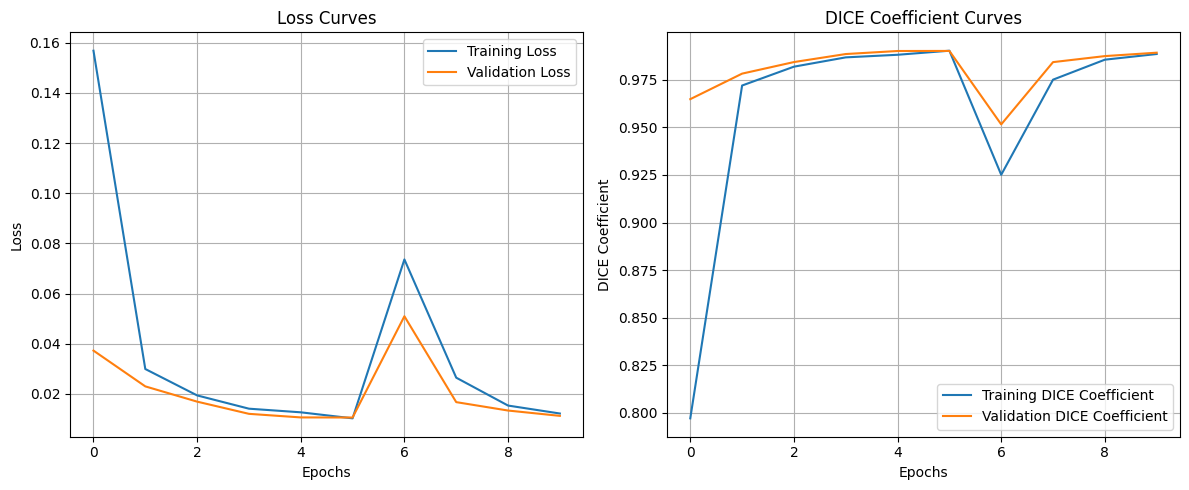

In [14]:
# Plotting the training and validation losses and DICE coefficients
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(train_dcs, label='Training DICE Coefficient')
plt.plot(val_dcs, label='Validation DICE Coefficient')
plt.title('DICE Coefficient Curves')
plt.xlabel('Epochs')
plt.ylabel('DICE Coefficient')
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

In [24]:
def random_images_inference(image_tensors, mask_tensors, model_pth, device):
    model = UNet(in_channels=3, out_channels=1).to(device)
    model.load_state_dict(torch.load(model_pth, map_location=torch.device(device)))

    transform = transforms.Compose([
        transforms.Resize((512, 512))
    ])

    # Iterate for the images, masks and paths
    for image_pth, mask_pth in zip(image_tensors, mask_tensors):
        # Load the image
        img = transform(image_pth)
        
        # Predict the imagen with the model
        pred_mask = model(img.unsqueeze(0))
        pred_mask = pred_mask.squeeze(0).permute(1,2,0)
        
        # Load the mask to compare
        mask = transform(mask_pth).permute(1, 2, 0).to(device)
        
        print(f" DICE coefficient: {round(float(dice_coefficient(pred_mask, mask)),5)}")
        
        # Show the images
        img = img.cpu().detach().permute(1, 2, 0)
        pred_mask = pred_mask.cpu().detach()
        pred_mask[pred_mask < 0] = 0
        pred_mask[pred_mask > 0] = 1
        
        plt.figure(figsize=(15, 16))
        plt.subplot(131), plt.imshow(img), plt.title("original")
        plt.subplot(132), plt.imshow(pred_mask, cmap="gray"), plt.title("predicted")
        plt.subplot(133), plt.imshow(mask, cmap="gray"), plt.title("mask")
        plt.show()

In [25]:
n = 10

image_tensors = []
mask_tensors = []
image_paths = []

for _ in range(n):
    random_index = random.randint(0, len(val_dataloader.dataset) - 1)
    random_sample = val_dataloader.dataset[random_index]

    image_tensors.append(random_sample[0])  
    mask_tensors.append(random_sample[1]) 

 DICE coefficient: 0.99302


/tmp/ipykernel_47905/1082172306.py:21: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print(f" DICE coefficient: {round(float(dice_coefficient(pred_mask, mask)),5)}")


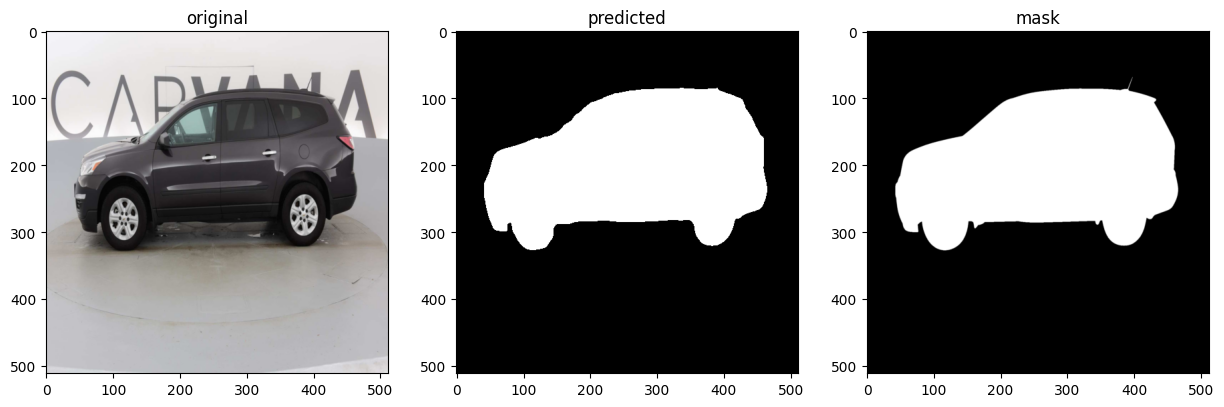

 DICE coefficient: 0.99138


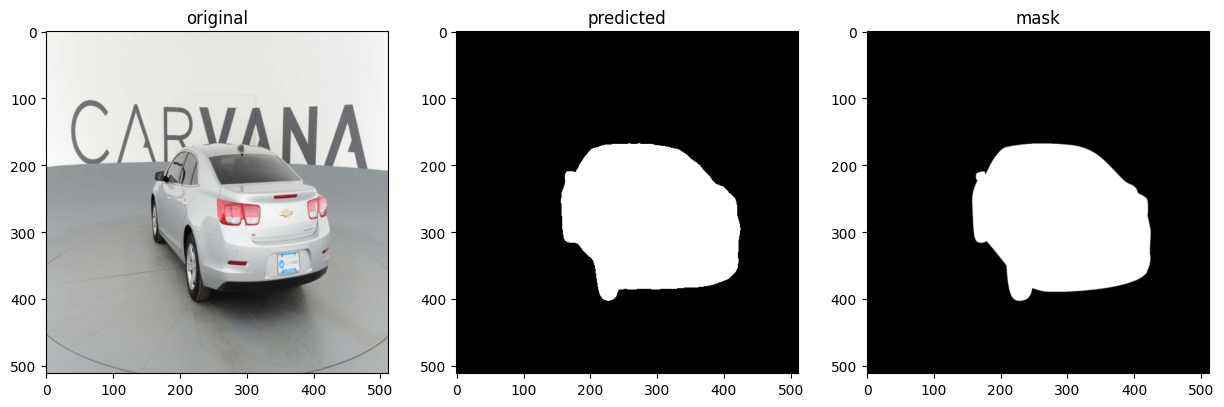

 DICE coefficient: 0.98832


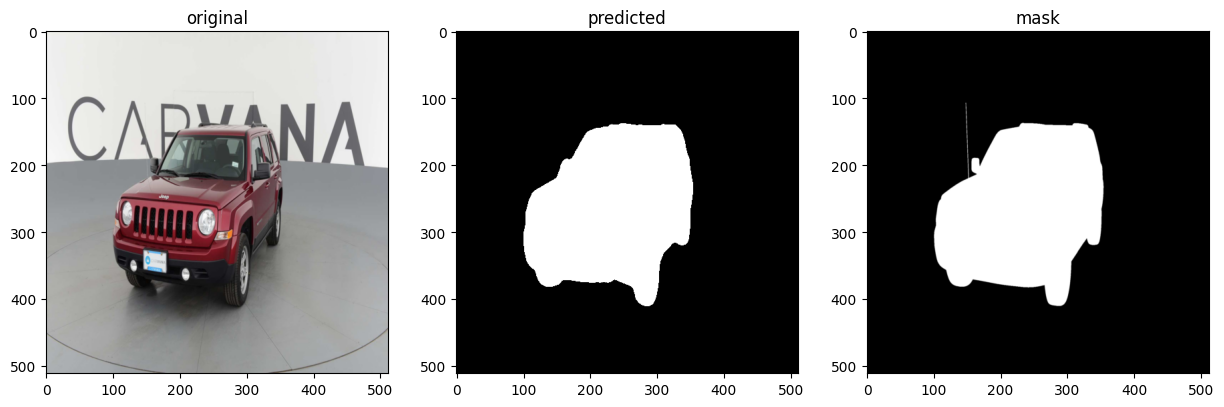

 DICE coefficient: 0.99257


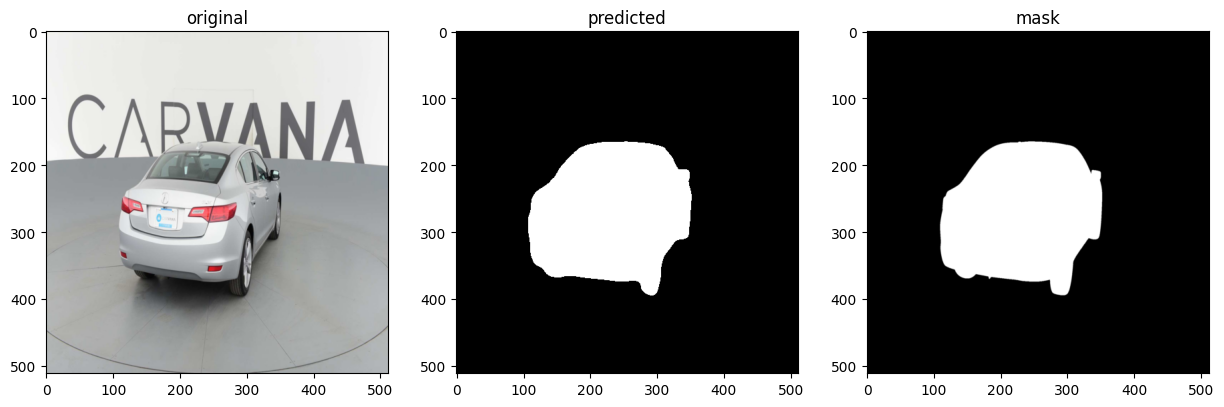

 DICE coefficient: 0.99045


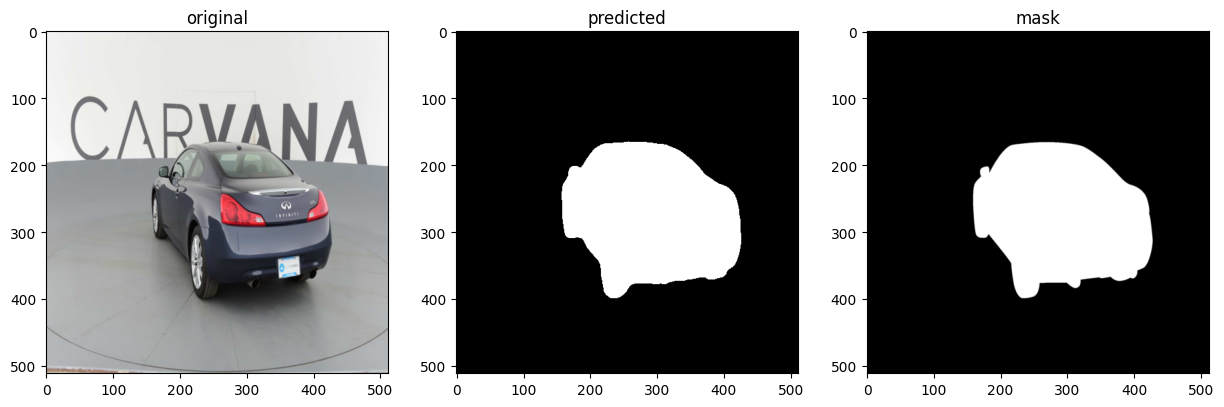

 DICE coefficient: 0.98521


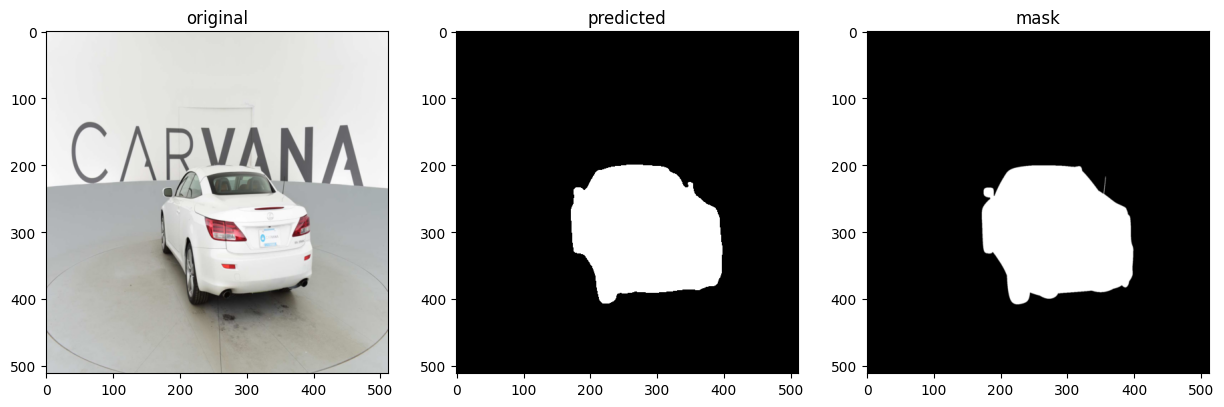

 DICE coefficient: 0.99052


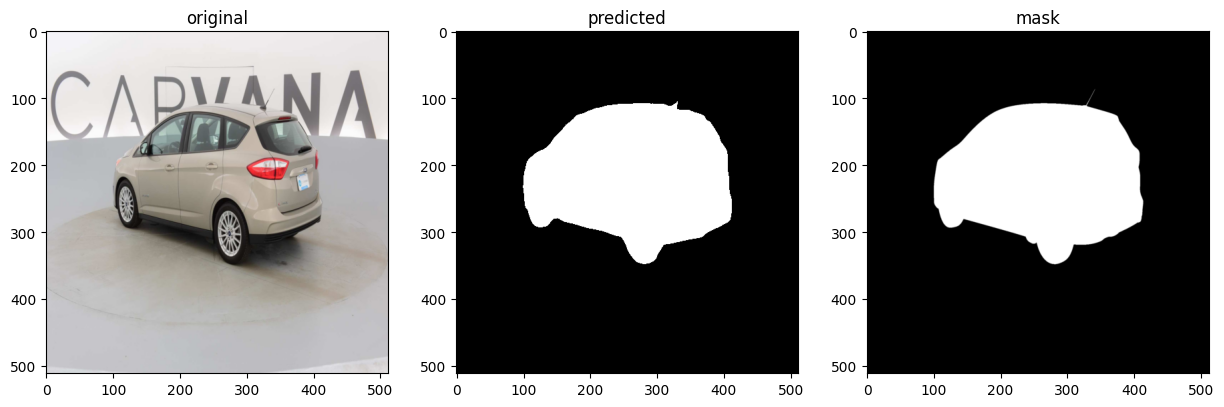

 DICE coefficient: 0.99159


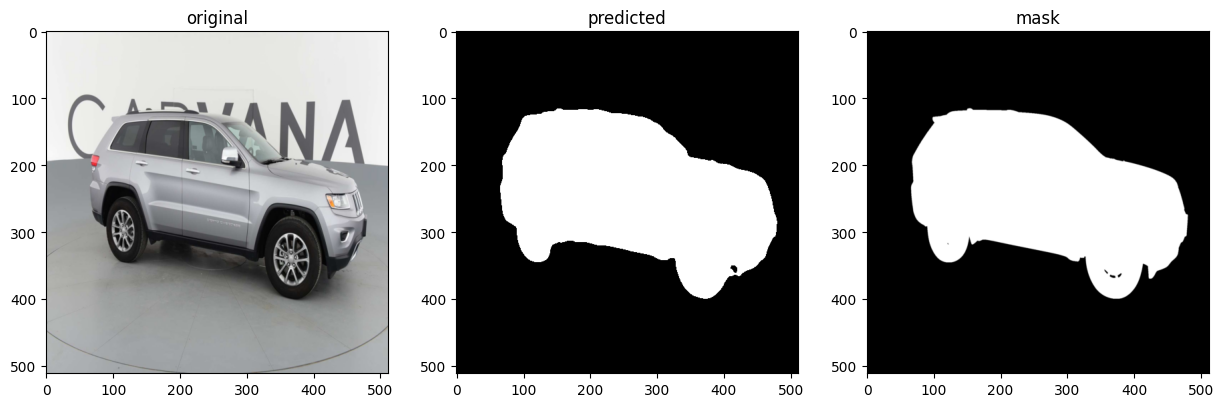

 DICE coefficient: 0.98985


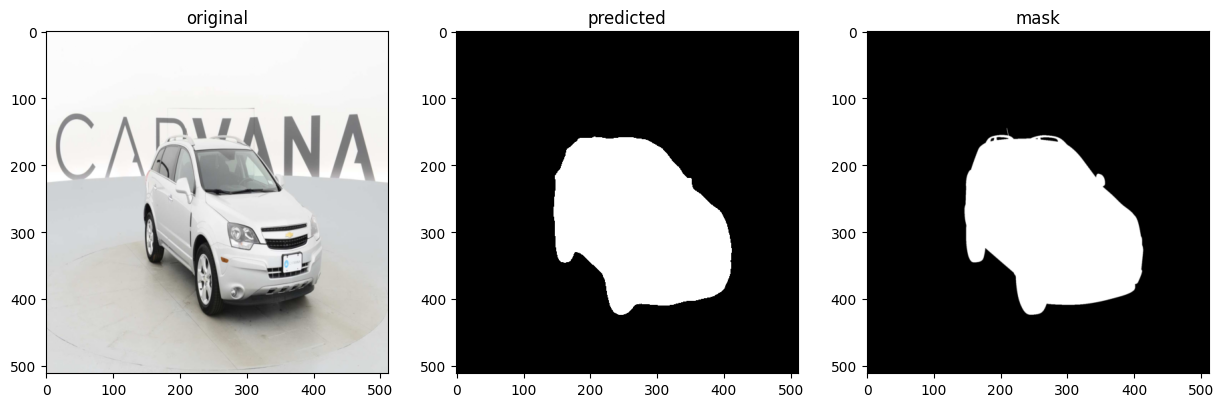

 DICE coefficient: 0.99265


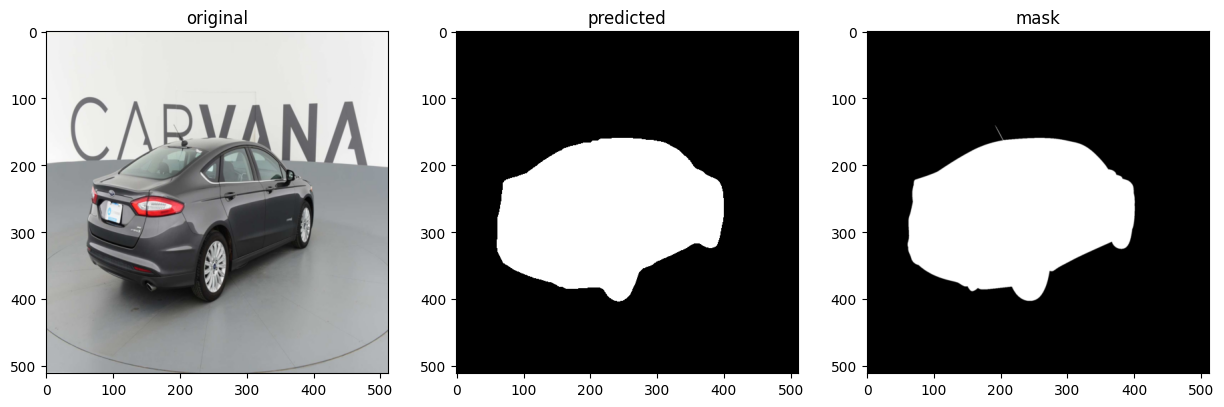

In [26]:
model_path = './carvana_unet.ckpt'

random_images_inference(image_tensors, mask_tensors, model_path, device="cpu")